# Cleland Experiment 3 — MALDI-MSI Liver Zonation Analysis

## Overview
This notebook analyses negative-mode MALDI mass spectrometry imaging (MALDI-MSI) data from two mouse liver sections:
- **females2_section3** — female mouse
- **males2_section3** — male mouse

The primary goals are:
1. Identify **spatially structured (zonated) lipids** across the liver lobule
2. Detect **sex differences** in lipid abundance, resolved by hepatic zone

## Biological background
The liver lobule is organised radially between portal triads (periportal zone) and central veins (pericentral zone). Zone assignment uses a two-pass Leiden clustering strategy for both ROIs. For both ROIs, co-registered Visium HD cluster masks are used as a visual reference to confirm which Leiden clusters correspond to which zone.

## Data
- MALDI data: `adata.X` = raw (no normalisation), `adata.layers['RMS_intensities']` = RMS-normalised
- Visium HD cluster masks (both ROIs): binary 8-bit TIFs at `visium_clusters/female_cluster1.tif` / `female_cluster2.tif` and `male_cluster1.tif` / `male_cluster2.tif`

## Key design decisions
| Step |  Why |
|------|-----|
| Leiden clustering (Pass 1) | Remove background/vessels |
| Leiden clustering (Pass 2) |  Zone assignment on clean tissue |
| Visium HD (both ROIs) | Visual reference only — confirms Leiden cluster → zone mapping |
| Moran's I | Measure of ion spatial autocorrelation |
| Vessel correlation | Pearson r vs heme+bile reference image |
| Differential analysis | Computes fold changes |
| ROC AUC | Zone separability per ion |

## Workflow summary
```
Section 1 — Load & preprocess
Section 2 — Visium HD co-registration (both ROIs, visual reference only)
Section 3 — Leiden clustering (both ROIs)
    → Pass 1: remove background/vessels
    → Pass 2: cluster tissue-only pixels
Section 4 — Visium HD diagnostic
SEction 5 — Moran's I spatial autocorrelation
Section 6 — Vessel correlation score
Section 7 — Differential analysis
Section 8 — Plots
Section 9 — Stats
Section 10 — Export to SCiLS
```

## Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import napari
import tifffile
import scipy.ndimage
from scipy.stats import pearsonr
from sklearn.metrics import roc_auc_score
from tqdm.notebook import tqdm
from IPython.display import display
from datetime import date

import os
from scilslab import LocalSession
os.environ["SCILSMSSERVER"] = r"C:\Program Files\Bruker\SCiLS Lab\scilsMsServer.exe"

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
plt.rcParams.update({
    'figure.figsize': (5, 5),
    'font.family': 'Arial',
    'font.size': 7,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size': 3,
    'ytick.major.size': 3,
})

C:\Users\TOF-User\anaconda3\envs\scils_api\Lib\site-packages\dask\dataframe\__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
C:\Users\TOF-User\anaconda3\envs\scils_api\Lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


## Paths & config

In [2]:
p = Path.cwd()
p_results = p / "results"
p_results.mkdir(exist_ok=True)

p_data  = p / r"anndatas/20260115_VS_Cleland_Expt2_DAN_neg_recal.h5ad"
p_scils = Path(r"D:\Analysis\USERS\Cleland\expt2\scils_recal\20260115_VS_Cleland_Expt2_DAN_neg_recal.slx")

roi_female  = "slide2_sec3_female"
roi_male    = "slide5_sec2_male"
tissue_rois = [roi_female, roi_male]

# FISH
p_fish = p / "FISH_images"
p_fish_tifs = {
    roi_female: p_fish / "slide2_section3.tif",
    roi_male:   p_fish / "slide5_section2.tif",
}
fish_channel = 1  # Cyp2f2 RNA channel

p_affinder   = p_fish / "affinder"
p_affinder.mkdir(exist_ok=True)
p_affinder_txt = {
    roi_female: p_affinder / "slide2_sec3_female_affine_transform.txt", 
    roi_male:   p_affinder / "slide5_sec2_male_affine_transform.txt",
}

fish_thresholds = {
    roi_female: 13500,  # Cyp2f2 periportal threshold — adjust after inspection
    roi_male:   7500,
}

# Zone colours per sex
zone_colors_female = {'pericentral': '#bf2e2e', 'periportal': '#ff6969'}
zone_colors_male   = {'pericentral': '#205cbc', 'periportal': '#7ba7ff'}
roi_palettes = {
    roi_female: zone_colors_female,
    roi_male:   zone_colors_male,
}

## Functions

In [3]:
def bootstrap_log2fc_with_p(x1, x2, rng, n_boot=1000, sample_frac=0.5):
    """
    Bootstrap log2FC and empirical two-sided p-value.
    Parameters:
    - x1, x2:       raw intensity vectors for group 1 and group 2
    - rng:          numpy random generator for reproducibility
    - n_boot:       number of bootstrap iterations
    - sample_frac:  fraction of pixels sampled per iteration
    Returns: (mean_fc, p) — positive mean_fc = x1 higher
    """
    epsilon = 1e-6
    fc_vals = []
    for _ in range(n_boot):
        s1 = rng.choice(x1, size=int(len(x1) * sample_frac), replace=True)
        s2 = rng.choice(x2, size=int(len(x2) * sample_frac), replace=True)
        fc_vals.append(np.log2((np.mean(s1) + epsilon) / (np.mean(s2) + epsilon)))
    fc_vals = np.array(fc_vals)
    mean_fc = np.mean(fc_vals)
    p = 2 * min(np.mean(fc_vals <= 0), np.mean(fc_vals >= 0))
    p = max(p, 1.0 / n_boot)  # floor at minimum resolvable p-value
    p = min(p, 1.0)
    return mean_fc, p


def run_fc_analysis(anndata, group1, group2, groupby, foldchange_key, pval_key,
                    mask_obs=None, n_boot=1000, sample_frac=0.5, random_state=0):
    """
    Bootstrap log2FC and p-values for all ions, stored in anndata.var.
    Uses anndata.raw.X (non-normalised intensities).
    Parameters:
    - group1, group2:           values in anndata.obs[groupby] to compare (group1 / group2)
    - groupby:                  obs column defining the groups
    - foldchange_key, pval_key: column names to write into anndata.var
    - mask_obs:                 optional pixel subset (e.g. one zone only)
    - n_boot:                   number of bootstrap iterations
    - sample_frac:              fraction of pixels sampled per iteration
    - random_state:             random seed
    """
    rng = np.random.default_rng(random_state)
   
    if mask_obs is not None:
        g1 = (anndata.obs[groupby] == group1) & mask_obs
        g2 = (anndata.obs[groupby] == group2) & mask_obs
    else:
        g1 = anndata.obs[groupby] == group1
        g2 = anndata.obs[groupby] == group2
    
    features = anndata.var_names
    X = anndata.raw.X
    
    log2fc_stats, pval_stats = [], []
    for i, _ in enumerate(tqdm(features, desc="FC")):
        lfc, pval = bootstrap_log2fc_with_p(
            X[g1, i].ravel(), X[g2, i].ravel(),
            rng, n_boot=n_boot, sample_frac=sample_frac)
        log2fc_stats.append(lfc)
        pval_stats.append(pval)

    anndata.var[foldchange_key] = log2fc_stats
    anndata.var[pval_key]       = pval_stats


def run_roc_analysis(anndata, group1, group2, groupby, key_added, mask_obs=None):
    """
    ROC AUC per ion between two groups, stored in anndata.var.
    Uses anndata.raw.X (non-normalised intensities).
    Parameters:
    - group1:    positive class (AUC = 1.0 → perfectly enriched in group1)
    - group2:    negative class (AUC = 0.0 → perfectly enriched in group2)
    - groupby:   obs column defining the groups
    - key_added: column name to write AUC scores into anndata.var
    - mask_obs:  optional pixel subset (e.g. one ROI only)
    """

    if mask_obs is not None:
        pixel_mask = anndata.obs[groupby].isin([group1, group2]) & mask_obs
    else:
        pixel_mask = anndata.obs[groupby].isin([group1, group2])
    
    labels = anndata.obs.loc[pixel_mask, groupby].map({group1: 1, group2: 0}).values
    features = anndata.var_names
    X = anndata.raw.X[pixel_mask, :]

    scores = []
    for i, _ in enumerate(tqdm(features, desc="ROC")):
        auc = roc_auc_score(labels, np.asarray(X[:, i]).ravel())
        scores.append(auc)
    anndata.var[key_added] = scores
    

def import_group_to_scils(session, feature_list_name, names, mzs, columns=None):
    """
    Write a feature list with optional numeric columns to a SCiLS session.
    Parameters:
    - session:             LocalSession object
    - feature_list_name:   name of the feature list to create
    - names:               ion names
    - mzs:                 DataFrame with 'mz_low' and 'mz_high' columns
    - columns:             optional dict {column_name: values} to attach
    """
    ft      = session.dataset_proxy.feature_table
    fl_id   = ft.create_empty_feature_list(feature_list_name)
    ft.write_mz_features(fl_id, list(zip(mzs["mz_low"], mzs["mz_high"], names)))
    if columns:
        features    = ft.get_features(fl_id)
        feature_ids = features['id'].tolist()
        for col_name, values in columns.items():
            ft.write_column(col_name, feature_ids, list(values))
    return fl_id

---
# Section 1 — Load & preprocess

Loads the AnnData object, subsets to the two tissue ROIs, and prepares two data layers:
- `adata.raw` — non-normalised intensities, frozen for all differential analyses
- `adata.X` — RMS-normalised intensities, used for clustering

`filter_cells(min_genes=10)` removes pixels with very sparse signal. `filter_genes(min_cells=50)` removes features detected in fewer than 50 pixels.

In [4]:
adata = sc.read(p_data)
adata = adata[adata.obs["ROI"].isin(tissue_rois)].copy()

sc.pp.filter_cells(adata, min_genes=10)
sc.pp.filter_genes(adata, min_cells=50)

print(adata)

adata.raw = adata
adata.X = adata.layers['RMS_intensities'].copy()

AnnData object with n_obs × n_vars = 380950 × 373
    obs: 'ROI', 'x_pixel', 'y_pixel', 'n_genes'
    var: 'mz_low', 'mz_high', 'name', 'feature_name', 'n_cells'
    uns: 'feature_list', 'region_name', 'scils_file'
    obsm: 'spatial'
    layers: 'RMS_intensities'


---
# Section 2 — FISH co-registration

Registers the FISH images to the MALDI pixel coordinate space so the label image is available as a spatial reference when interpreting Leiden clusters later. Affine transform is estimated in napari and applied with `order=0` (nearest-neighbour) to preserve integer labels exactly.

## 2a — Co-registration via Napari Affinder

In [5]:
label_imgs = {}

for roi_label in tissue_rois:
    label_img = np.flip(tifffile.imread(p_fish_tifs[roi_label])[fish_channel], axis=0)
    label_imgs[roi_label] = label_img

    if not p_affinder_txt[roi_label].exists():
        adata_roi = adata[adata.obs['ROI'] == roi_label].copy()
        px  = adata_roi.obs[['x_pixel', 'y_pixel']].values
        tic = np.array(adata_roi.X.sum(axis=1)).flatten()
        img_maldi = np.zeros((px[:, 1].max() + 1, px[:, 0].max() + 1))
        img_maldi[px[:, 1], px[:, 0]] = tic
        
        viewer = napari.Viewer()
        viewer.add_image(img_maldi, name=f"MALDI_ref_{roi_label}")
        viewer.add_image(label_img, name=f"visium_labels_moving_{roi_label}")
        napari.run()
    else:
        print(f"Transform already exists for {roi_label}, skipping napari")

Transform already exists for slide2_sec3_female, skipping napari
Transform already exists for slide5_sec2_male, skipping napari


## 2b — Apply transform, inspect threshold, assign fish_zone

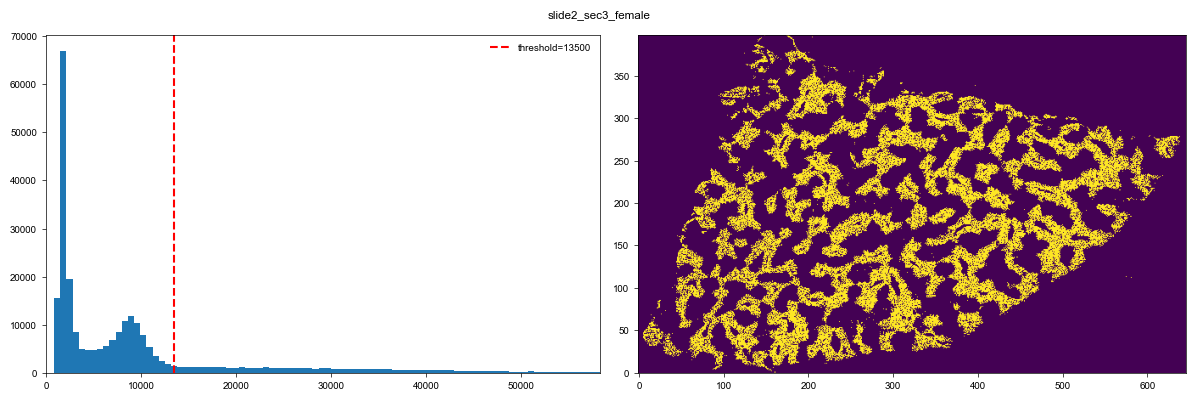

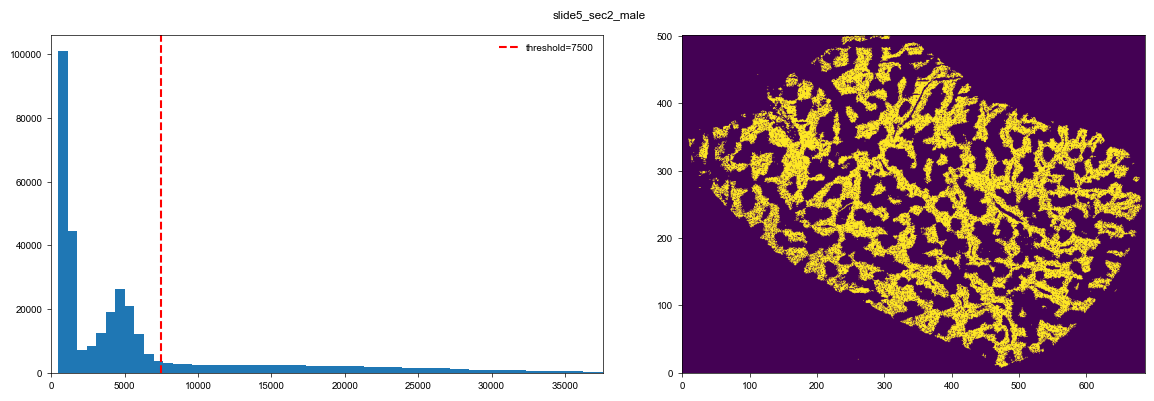

In [16]:
# Apply affine transform and inspect Cyp2f2 threshold
# Adjust fish_thresholds in config if needed, then rerun zone assignment cell
label_registered = {}

for roi_label in tissue_rois:
    affine_matrix = np.loadtxt(p_affinder_txt[roi_label], delimiter=",")
    px = adata[adata.obs["ROI"] == roi_label].obs[["x_pixel", "y_pixel"]].values
    img_shape = (px[:, 1].max() + 1, px[:, 0].max() + 1)

    label_registered[roi_label] = scipy.ndimage.affine_transform(
        label_imgs[roi_label], np.linalg.inv(affine_matrix),
        output_shape=img_shape,
        order=0
    )

    img = label_registered[roi_label]
    threshold = fish_thresholds[roi_label]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(img[img > 0].flatten(), bins=100)
    axes[0].axvline(threshold, color="red", ls="--", label=f"threshold={threshold}")
    axes[0].set_xlim(0, np.percentile(img[img > 0], 99))
    axes[0].legend(fontsize=7, frameon=False)
    axes[1].imshow(img > threshold, cmap="viridis", origin="lower")
    plt.suptitle(roi_label)
    plt.tight_layout()
    plt.savefig(p_results / f'FISH_threshold_{roi_label}.pdf', dpi=300, bbox_inches='tight')
    plt.show()

In [7]:
# Assign fish_zone: Cyp2f2+ = periportal, Cyp2f2- = pericentral
for roi_label in tissue_rois:
    mask = adata.obs["ROI"] == roi_label
    px = adata[mask].obs[["x_pixel", "y_pixel"]].values
    zone_mask = label_registered[roi_label] > fish_thresholds[roi_label]
    spot_zones = zone_mask[px[:, 1], px[:, 0]]
    adata.obs.loc[mask, "fish_zone"] = np.where(spot_zones, "periportal", "pericentral")

---
# Section 3 — Leiden clustering 

Two-pass strategy:
1. **Pass 1** — cluster all pixels to identify background/vessels and filter them out
2. **Pass 2** — re-cluster filtered data to assign periportal / pericentral zones

In [17]:
# Pass 1 — background/vessel removal, specify which clusters to keep
leiden_res_pass1 = 0.1
ontissue_clusters = {
    roi_female: ['0'],
    roi_male:   ['0'],
}

# Pass 2 — zone clustering
leiden_res_pass2 = 0.15
periportal_clusters = {
    roi_female: ['1'],
    roi_male:   ['0'],
}
pericentral_clusters = {
    roi_female: ['0'],
    roi_male:   ['1'],
}

C:\Users\TOF-User\anaconda3\envs\scils_api\Lib\site-packages\squidpy\pl\_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


C:\Users\TOF-User\anaconda3\envs\scils_api\Lib\site-packages\squidpy\pl\_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


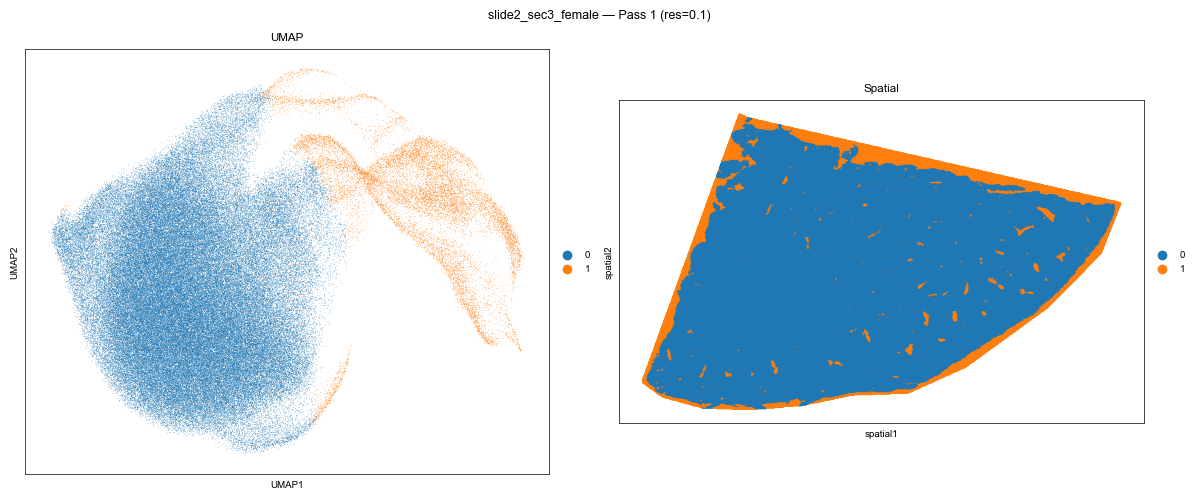

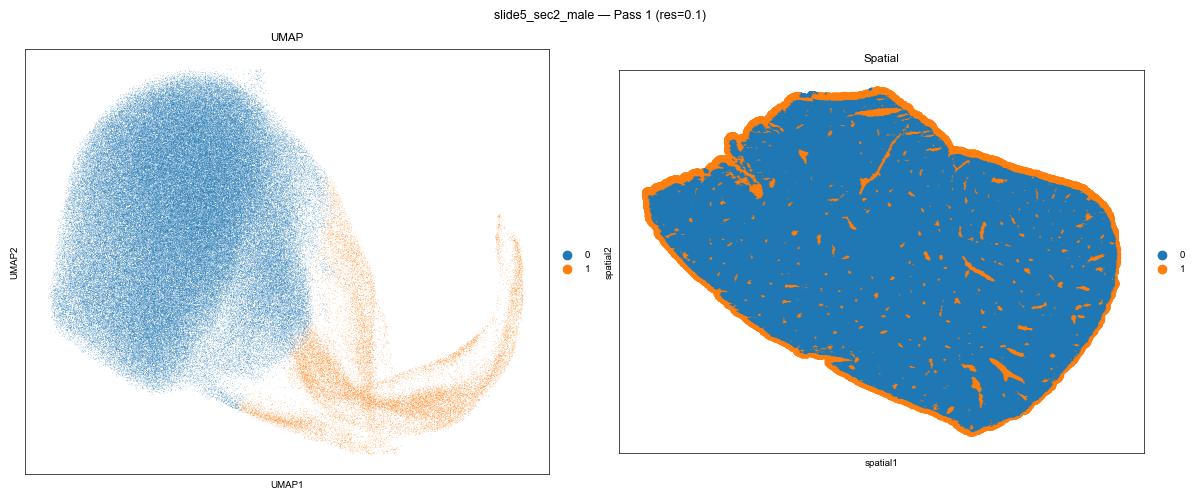

In [11]:
# ── 3a: Pass 1 — cluster all pixels to identify background/vessels ────────────
figs_pass1 = []
adata.obs['tissue_pixel'] = False

for roi_label in tissue_rois:
    a = adata[adata.obs['ROI'] == roi_label].copy()
    sc.pp.log1p(a, base=10)
    sc.pp.scale(a)
    sc.tl.pca(a)
    sc.pp.neighbors(a, n_neighbors=30, n_pcs=15, random_state=42)
    sc.tl.umap(a, random_state=42)
    sc.tl.leiden(a, resolution=leiden_res_pass1, key_added='leiden_pass1', random_state=42)

    # save to adata.obs
    adata.obs.loc[a.obs.index, f'leiden_pass1_{roi_label}'] = a.obs['leiden_pass1'].astype(str)
    adata.obs.loc[a.obs.index, 'tissue_pixel'] = a.obs['leiden_pass1'].isin(ontissue_clusters[roi_label])

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f'{roi_label} — Pass 1 (res={leiden_res_pass1})', fontsize=9)
    sc.pl.umap(a, color='leiden_pass1', ax=axes[0], show=False, title='UMAP')
    sq.pl.spatial_scatter(a, shape=None, color='leiden_pass1', size=2,
                          ax=axes[1], title='Spatial')
    plt.tight_layout()
    plt.savefig(p_results / f'clustering_pass1_{roi_label}.pdf', dpi=300, bbox_inches='tight')
    figs_pass1.append(fig)

for fig in figs_pass1:
    display(fig); plt.close(fig)

C:\Users\TOF-User\anaconda3\envs\scils_api\Lib\site-packages\squidpy\pl\_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


C:\Users\TOF-User\anaconda3\envs\scils_api\Lib\site-packages\squidpy\pl\_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


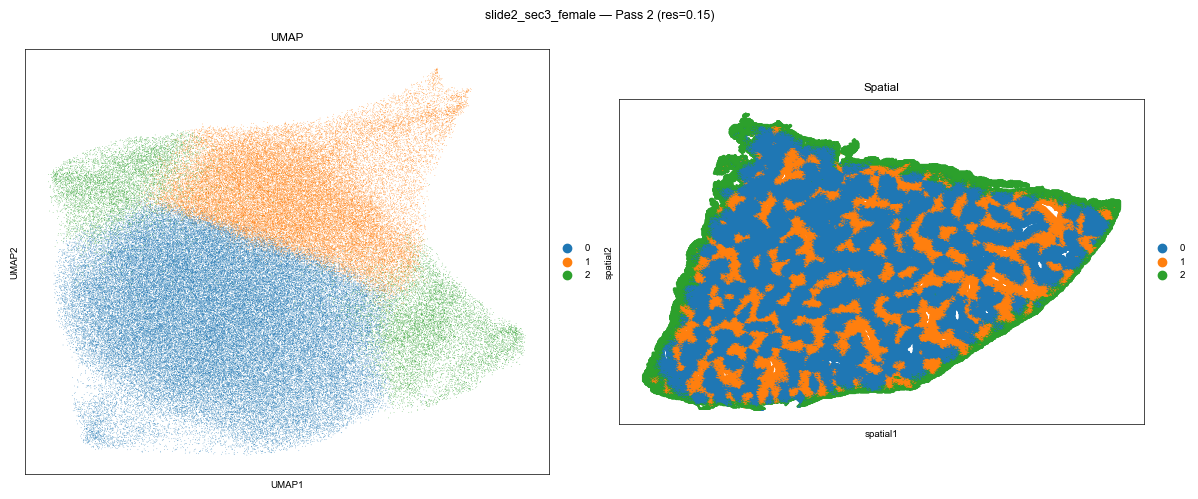

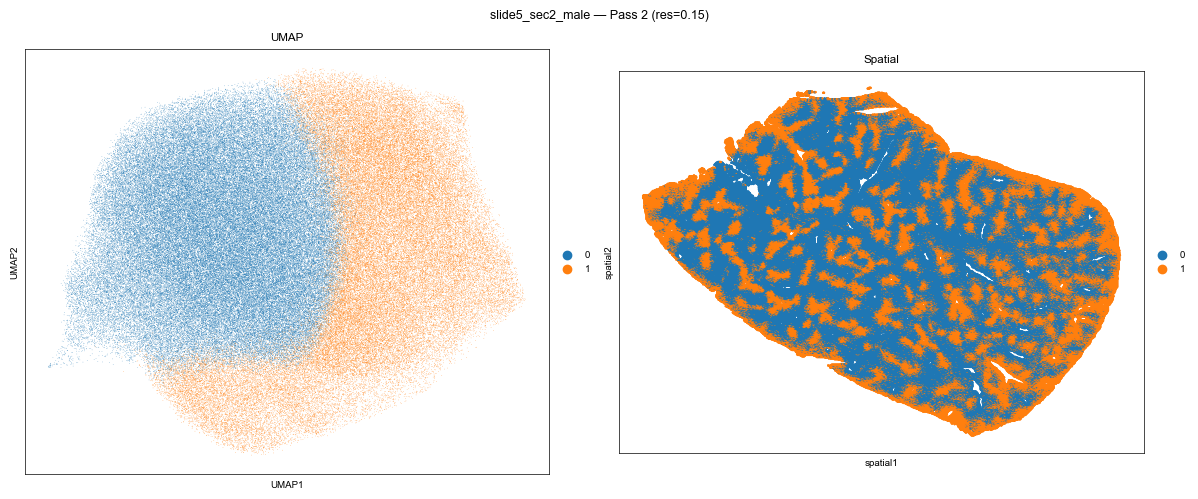

In [18]:
# ── 3b: Pass 2 — cluster tissue-only pixels ───────────────────────────────────
figs_pass2 = []
adata.obs['maldi_zone'] = 'unassigned'

for roi_label in tissue_rois:
    mask = (adata.obs['ROI'] == roi_label) & adata.obs['tissue_pixel']
    a = adata[mask].copy()
    sc.pp.log1p(a, base=10)
    sc.pp.scale(a)
    sc.tl.pca(a)
    sc.pp.neighbors(a, n_neighbors=30, n_pcs=15, random_state=42)
    sc.tl.umap(a, random_state=42)
    sc.tl.leiden(a, resolution=leiden_res_pass2, key_added='leiden_pass2', random_state=42)

    # write back to adata
    adata.obs.loc[a.obs.index, f'leiden_pass2_{roi_label}'] = a.obs['leiden_pass2'].astype(str)
    zone_series = (
        a.obs['leiden_pass2'].astype(str).map(
             {c: 'periportal'  for c in periportal_clusters[roi_label]} |
             {c: 'pericentral' for c in pericentral_clusters[roi_label]})
         .fillna('unassigned')
    )
    adata.obs.loc[a.obs.index, 'maldi_zone'] = zone_series

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f'{roi_label} — Pass 2 (res={leiden_res_pass2})', fontsize=9)
    sc.pl.umap(a, color='leiden_pass2', ax=axes[0], show=False, title='UMAP')
    sq.pl.spatial_scatter(a, shape=None, color='leiden_pass2', size=2,
                          ax=axes[1], title='Spatial')
    plt.tight_layout()
    plt.savefig(p_results / f'clustering_pass2_{roi_label}.pdf', dpi=300, bbox_inches='tight')
    figs_pass2.append(fig)

for fig in figs_pass2:
    display(fig); plt.close(fig)

In [20]:
# ── 3c: Summary ───────────────────────────────────────────────────────────────
print(adata.obs.groupby(['ROI', 'maldi_zone']).size())
print(f"\non_tissue pixels: {adata.obs['tissue_pixel'].sum()} / {adata.n_obs}")

ROI                 maldi_zone 
slide2_sec3_female  pericentral     89626
                    periportal      42353
                    unassigned      33712
slide5_sec2_male    pericentral     75642
                    periportal     116570
                    unassigned      23047
dtype: int64

on_tissue pixels: 341698 / 380950


C:\Users\TOF-User\AppData\Local\Temp\ipykernel_9520\2872068627.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(adata.obs.groupby(['ROI', 'maldi_zone']).size())


---
# Section 4 — FISH diagnostic

Confirms that the Leiden cluster → zone assignment for both ROIs agrees with FISH ground truth data

**Plots:**
- Spatial side-by-side: `maldi_zone` (Leiden-derived) vs FISH thresholded image
- Spatial overlap: periportal agreement between Leiden and FISH, colour-coded by concordance

C:\Users\TOF-User\anaconda3\envs\scils_api\Lib\site-packages\squidpy\pl\_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
C:\Users\TOF-User\anaconda3\envs\scils_api\Lib\site-packages\squidpy\pl\_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


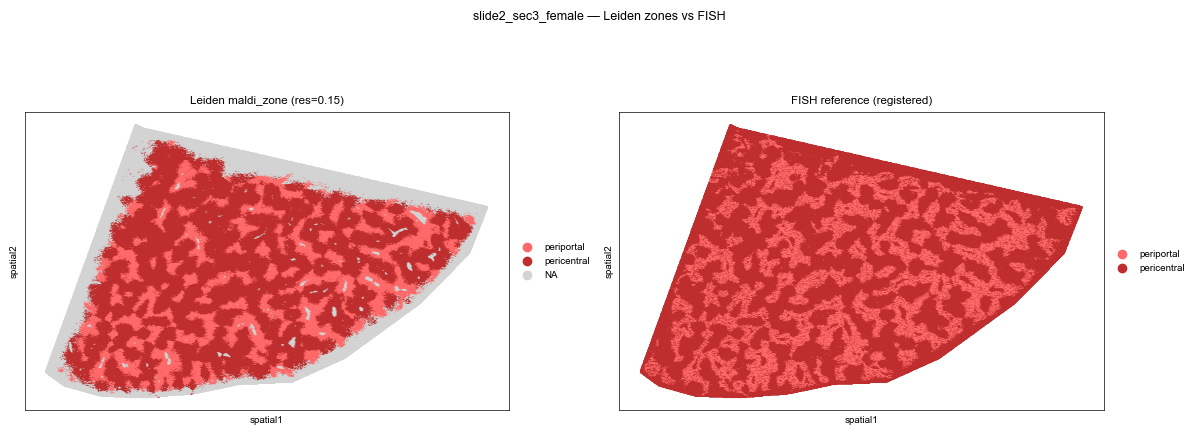

C:\Users\TOF-User\anaconda3\envs\scils_api\Lib\site-packages\squidpy\pl\_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
C:\Users\TOF-User\anaconda3\envs\scils_api\Lib\site-packages\squidpy\pl\_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


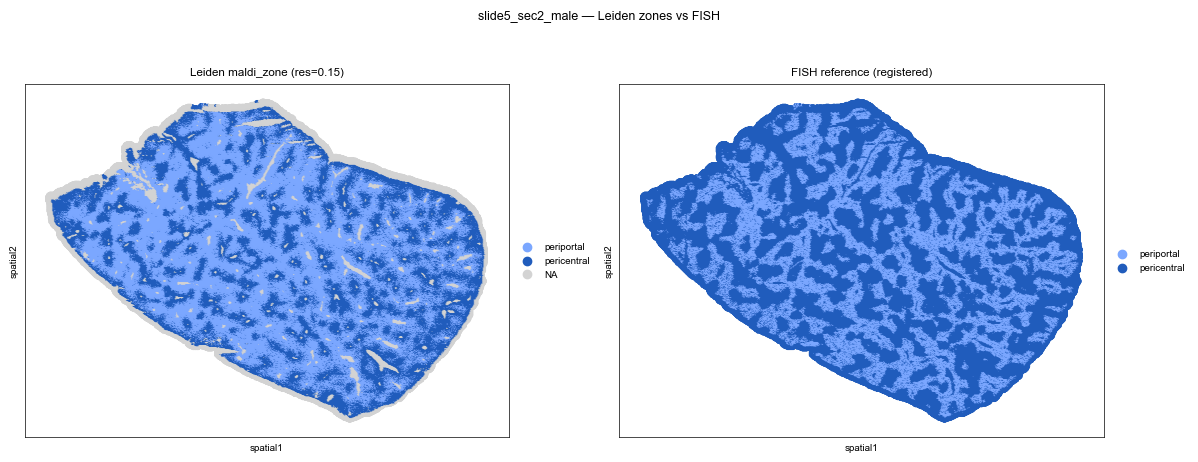

In [23]:
# Spatial side-by-side: Leiden maldi_zone vs registered FISH image (both ROIs)
for roi_label, roi_colors in [(roi_female, zone_colors_female), (roi_male, zone_colors_male)]:
    mask = (adata.obs['ROI'] == roi_label)
    a = adata[mask].copy()
    cats = ['periportal', 'pericentral']
    a.obs['maldi_zone'] = pd.Categorical(a.obs['maldi_zone'], categories=cats)
    a.obs['fish_zone'] = pd.Categorical(a.obs['fish_zone'], categories=cats)  # already exists
    palette_cmap = ListedColormap([roi_colors[c] for c in cats])
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f'{roi_label} — Leiden zones vs FISH', fontsize=9)
    sq.pl.spatial_scatter(a, shape=None, color='maldi_zone', size=2,
                          palette=palette_cmap, ax=axes[0],
                          na_color='lightgrey',
                          title=f'Leiden maldi_zone (res={leiden_res_pass2})')
    sq.pl.spatial_scatter(a, shape=None, color='fish_zone', size=2,
                          palette=palette_cmap, ax=axes[1],
                          title='FISH reference (registered)')
    plt.tight_layout()
    plt.savefig(p_results / f'fish_diagnostic_{roi_label}.pdf', dpi=300, bbox_inches='tight')
    plt.show()

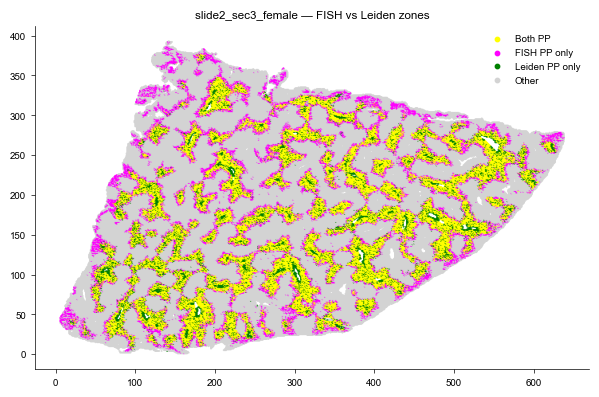

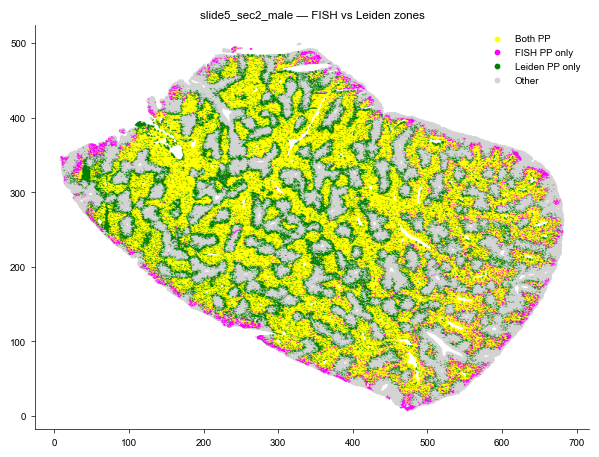

In [33]:
# Spatial overlap: FISH vs Leiden maldi_zone (both ROIs)
for roi_label in tissue_rois:
    mask = (adata.obs['ROI'] == roi_label) & (adata.obs['tissue_pixel'] == 1)
    a = adata[mask].copy()
    df = a.obs[['fish_zone', 'maldi_zone', 'x_pixel', 'y_pixel']].copy()
    df['color'] = np.select(
        [
            (df['fish_zone'] == 'periportal') & (df['maldi_zone'] == 'periportal'),
            (df['fish_zone'] == 'periportal'),
            (df['maldi_zone'] == 'periportal'),
        ],
        ['yellow', 'magenta', 'green'],
        default='lightgrey'
    )
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(df['x_pixel'], df['y_pixel'], c=df['color'], s=2, linewidths=0, alpha=0.8)
    ax.set_aspect('equal')
    ax.set_title(f'{roi_label} — FISH vs Leiden zones')
    for legend_label, color in [('Both PP', 'yellow'), ('FISH PP only', 'magenta'),
                                 ('Leiden PP only', 'green'), ('Other', 'lightgrey')]:
        ax.scatter([], [], c=color, s=10, label=legend_label)
    ax.legend(fontsize=7, frameon=False)
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.savefig(p_results / f'fish_vs_leiden_overlap_{roi_label}.pdf', dpi=300, bbox_inches='tight')
    plt.show()

---
# Section 5 — Moran's I spatial autocorrelation

Quantifies spatial autocorrelation for each detected ion. Moran's I ranges from 0 (dispersed) to 1 (clustered). RMS-normalised intensities are used, as they recapitulate zonation better and remove some of the tissue-wide gradients.

**Purpose:** Ions with low Moran's I are not spatially organised and are unlikely to reflect true zonation biology. The `spatially_variable` flag (I > 0.1 in at least one ROI) is used downstream to visually distinguish meaningful hits — but is not used to filter the differential analysis itself.

In [34]:
moran_thresh = 0.1
pval_thresh  = 0.05

for roi_label in tissue_rois:
    mask      = (adata.obs['ROI'] == roi_label) & (adata.obs['tissue_pixel'] == 1) # to exclude vessels which would make everything more spatially correated
    adata_roi = adata[mask].copy()
    sq.gr.spatial_neighbors(adata_roi, coord_type="grid", n_neighs=4)
    sq.gr.spatial_autocorr(adata_roi, mode="moran", n_perms=1000)
    adata.var[f'moranI_{roi_label}']      = adata_roi.uns['moranI']['I']
    adata.var[f'moranI_pval_{roi_label}'] = adata_roi.uns['moranI']['pval_sim']

sv_r1 = (adata.var[f'moranI_{tissue_rois[0]}'] > moran_thresh) & \
         (adata.var[f'moranI_pval_{tissue_rois[0]}'] < pval_thresh)
sv_r2 = (adata.var[f'moranI_{tissue_rois[1]}'] > moran_thresh) & \
         (adata.var[f'moranI_pval_{tissue_rois[1]}'] < pval_thresh)
adata.var['spatially_variable'] = sv_r1 | sv_r2

print(f"Spatially variable: {adata.var['spatially_variable'].sum()} / {adata.n_vars}")

  0%|          | 0/1000 [00:00<?, ?/s]

  0%|          | 0/1000 [00:00<?, ?/s]

Spatially variable: 261 / 373


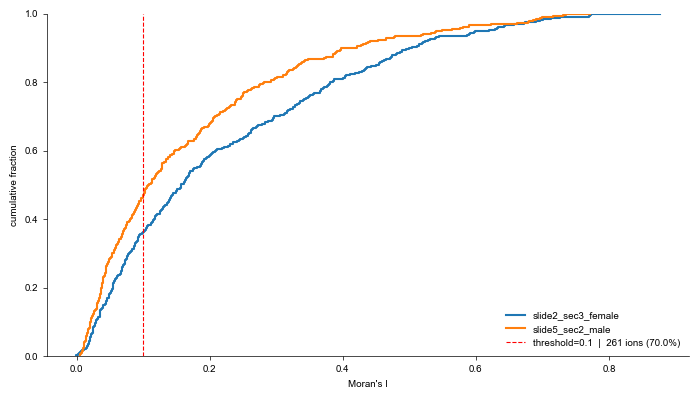

In [35]:
# ECDF — visualise number of ions selected by threshold
fig, ax = plt.subplots(figsize=(7, 4))

for roi_label in tissue_rois:
    sns.ecdfplot(adata.var[f'moranI_{roi_label}'], ax=ax, label=roi_label)

n_retained = adata.var['spatially_variable'].sum()
ax.axvline(moran_thresh, ls='--', lw=0.8, c='red',
           label=f'threshold={moran_thresh}  |  {n_retained} ions ({n_retained/adata.n_vars:.1%})')
ax.set_xlabel("Moran's I")
ax.set_ylabel('cumulative fraction')
ax.legend(fontsize=7, frameon=False)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(p_results / 'moranI_threshold.pdf', dpi=300, bbox_inches='tight')
plt.show()

---
# Section 6 — Vessel correlation score

For each ion, computes pixel-wise Pearson correlation against a combined vessel reference image
(heme + bile summed) derived from MALDI data. RMS-normalised inensities are used.

Ions with high correlation to the vessel image are likely vessel-enriched and may contaminate
periportal/pericentral comparisons due to spatial spillover. The score is stored in `adata.var`
and can be used as a filter downstream.


In [36]:
# ── Build vessel reference image and compute per-ion correlation ──────────────
bile_idx = adata.var['mz_low'].between(514.2, 514.3).values.nonzero()[0][0]
heme_idx = adata.var['mz_low'].between(615.1, 615.2).values.nonzero()[0][0]

vessel_ref = adata.X[:, bile_idx] + adata.X[:, heme_idx]

vessel_corr = np.array([
    pearsonr(adata.X[:, i], vessel_ref)[0]
    for i in range(adata.n_vars)
])
adata.var['vessel_corr'] = np.where(np.isfinite(vessel_corr), vessel_corr, 0.0)

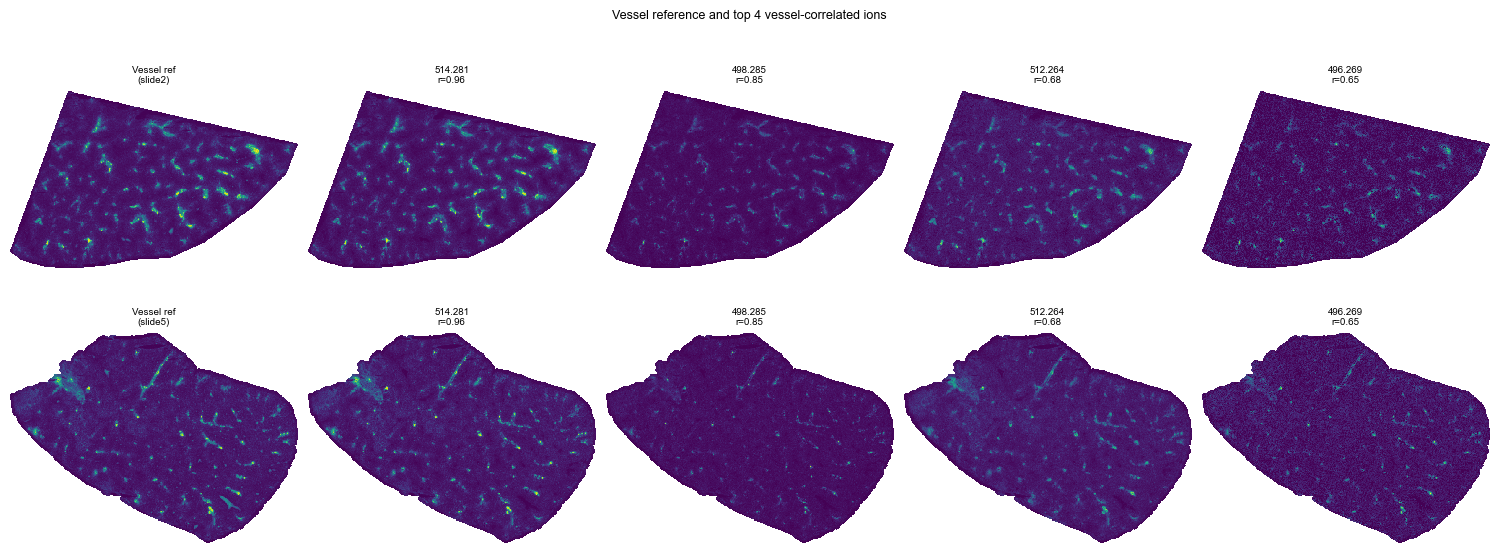

In [37]:
# ── Visualise vessel reference + top 4 correlated ions ───────────────────────
top4_idx = adata.var['vessel_corr'].nlargest(4).index

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('Vessel reference and top 4 vessel-correlated ions', fontsize=9)

for row, roi_label in enumerate(tissue_rois):
    a    = adata[adata.obs['ROI'] == roi_label]
    px   = a.obs[['x_pixel', 'y_pixel']].values
    ymax = px[:, 1].max() + 1
    xmax = px[:, 0].max() + 1

    # vessel reference
    ref_vals = np.asarray(vessel_ref).ravel()[adata.obs['ROI'] == roi_label]
    img = np.full((ymax, xmax), np.nan)
    img[px[:, 1], px[:, 0]] = ref_vals
    axes[row, 0].imshow(img, cmap='viridis', origin='lower',
                        interpolation='nearest', aspect='equal')
    axes[row, 0].set_title(f'Vessel ref\n({roi_label[:6]})', fontsize=7)
    axes[row, 0].axis('off')

    # top 4 ions
    for col, ion_name in enumerate(top4_idx, start=1):
        ion_idx = adata.var_names.get_loc(ion_name)
        vals    = np.asarray(adata[adata.obs['ROI'] == roi_label].X[:, ion_idx]).ravel()
        img = np.full((ymax, xmax), np.nan)
        img[px[:, 1], px[:, 0]] = vals
        mz   = adata.var.loc[ion_name, 'mz_low']
        corr = adata.var.loc[ion_name, 'vessel_corr']
        axes[row, col].imshow(img, cmap='viridis', origin='lower',
                              interpolation='nearest', aspect='equal')
        axes[row, col].set_title(f'{mz:.3f}\nr={corr:.2f}', fontsize=7)
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

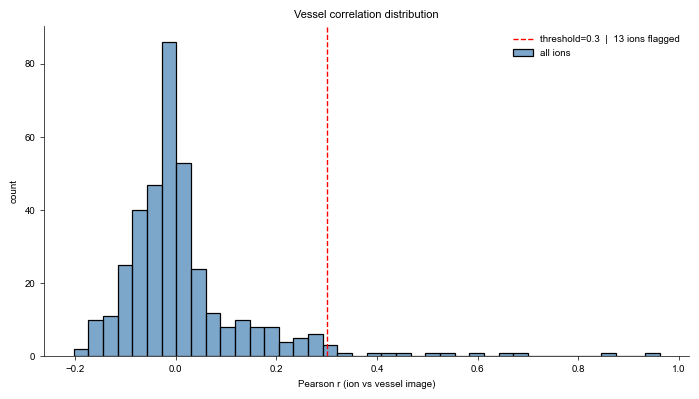

In [38]:
# ── Visualise vessel correlation distribution ─────────────────────────────────
vessel_corr_thresh = 0.3
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(adata.var['vessel_corr'], bins=40, ax=ax,
             color='steelblue', alpha=0.7, label='all ions')
ax.axvline(vessel_corr_thresh, ls='--', lw=1, c='red',
           label=f'threshold={vessel_corr_thresh}  |  {(adata.var["vessel_corr"] > vessel_corr_thresh).sum()} ions flagged')
ax.set_xlabel('Pearson r (ion vs vessel image)')
ax.set_ylabel('count')
ax.set_title('Vessel correlation distribution', fontsize=8)
ax.legend(fontsize=7, frameon=False)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(p_results / 'vessel_corr_distribution.pdf', dpi=300, bbox_inches='tight')
plt.show()

---
# Section 7 — Differential analysis

Bootstrap-based fold change is computed for all pairwise comparisons. All analyses use non-normalised intensities.

**Comparisons:**
| ID | Groups | Pixels used |
|----|--------|-------------|
| F_vs_M_pericentral | Female vs Male | Pericentral only |
| F_vs_M_periportal | Female vs Male | Periportal only |
| pericentral_vs_periportal_female | PC vs PP | Female section only |
| pericentral_vs_periportal_male | PC vs PP | Male section only |

**Outputs per comparison stored in `adata.var`:**
- `logfc_<comparison>` — mean bootstrap log2FC (positive = group1 higher)
- `pval_<comparison>` — empirical two-sided p-value

**ROC analysis:**
- Runs per ROI across all ions and ontissue pixels using `fish_zone` as the binary label (pericentral vs periportal)
- Output stored in `adata.var` as `zone_auc_{roi_label}`
- AUC = 1.0 → perfectly pericentral-enriched
- AUC = 0.5 → no zonation
- AUC = 0.0 → perfectly periportal-enriched

In [41]:
# Restore no-normalisation intensities for all the downstream analyses
adata.X = adata.raw.X

In [42]:
comparison = "F_vs_M_pericentral"
mask_obs   = (adata.obs["fish_zone"] == "pericentral") & (adata.obs['tissue_pixel'] == 1)

run_fc_analysis(adata, roi_female, roi_male, "ROI",
                f"logfc_{comparison}", f"pval_{comparison}",
                n_boot=1000, sample_frac=0.5, mask_obs=mask_obs)
del comparison, mask_obs

FC:   0%|          | 0/373 [00:00<?, ?it/s]

In [43]:
comparison = "F_vs_M_periportal"
mask_obs   = (adata.obs["fish_zone"] == "periportal") & (adata.obs['tissue_pixel'] == 1)

run_fc_analysis(adata, roi_female, roi_male, "ROI",
                f"logfc_{comparison}", f"pval_{comparison}",
                n_boot=1000, sample_frac=0.5, mask_obs=mask_obs)
del comparison, mask_obs

FC:   0%|          | 0/373 [00:00<?, ?it/s]

In [44]:
comparison = "pericentral_vs_periportal_female"
mask_obs   = (adata.obs["ROI"] == roi_female) & (adata.obs['tissue_pixel'] == 1)

run_fc_analysis(adata, "pericentral", "periportal", "fish_zone",
                f"logfc_{comparison}", f"pval_{comparison}",
                n_boot=1000, sample_frac=0.5, mask_obs=mask_obs)
del comparison, mask_obs

FC:   0%|          | 0/373 [00:00<?, ?it/s]

In [45]:
comparison = "pericentral_vs_periportal_male"
mask_obs   = (adata.obs["ROI"] == roi_male) & (adata.obs['tissue_pixel'] == 1)

run_fc_analysis(adata, "pericentral", "periportal", "fish_zone",
                f"logfc_{comparison}", f"pval_{comparison}",
                n_boot=1000, sample_frac=0.5, mask_obs=mask_obs)
del comparison, mask_obs

FC:   0%|          | 0/373 [00:00<?, ?it/s]

In [46]:
for roi_label in tissue_rois:
    mask_obs = (adata.obs['ROI'] == roi_label) & (adata.obs['tissue_pixel'] == 1)
    run_roc_analysis(adata, 'pericentral', 'periportal', 'fish_zone',
                     key_added=f'zone_auc_{roi_label}',
                     mask_obs=mask_obs)
del mask_obs

ROC:   0%|          | 0/373 [00:00<?, ?it/s]

ROC:   0%|          | 0/373 [00:00<?, ?it/s]

---

# Save data

In [47]:
adata.write(p / f"anndatas/expt2_analysed_{date.today().strftime('%Y%m%d')}.h5ad")
print("Saved full adata with all results")

Saved full adata with all results


---
# Section 8 — Plots

Two plots saved to `results/`:
- **`FC_vs_moranI_pc_pp.pdf`** — sex FC (F/M) vs Moran's I per zone
- **`FC_vs_moranI_zonation.pdf`** — zonation FC (PC/PP) vs Moran's I per sex

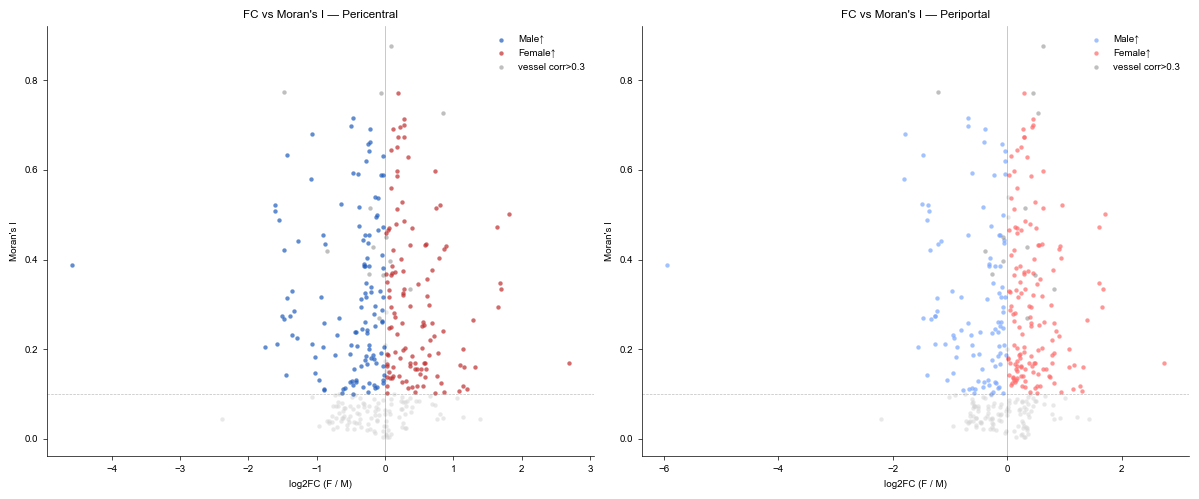

In [48]:
# Sex FC (F/M) vs Moran's I — per zone
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
df = adata.var.copy()
df['moranI'] = df[[f'moranI_{r}' for r in tissue_rois]].max(axis=1)
sv     = df['spatially_variable']
vessel = df['vessel_corr'] > vessel_corr_thresh

for ax, comparison, title, c_female, c_male in [
    (axes[0], 'F_vs_M_pericentral', 'Pericentral', '#bf2e2e', '#205cbc'),
    (axes[1], 'F_vs_M_periportal',  'Periportal',  '#ff6969', '#7ba7ff'),
]:
    fc_key  = f'logfc_{comparison}'
    pv_key  = f'pval_{comparison}'
    sig = df[pv_key] < 0.05
    fc  = df[fc_key]

    ax.scatter(df.loc[~sig | ~sv, fc_key], df.loc[~sig | ~sv, 'moranI'],
               c='lightgrey', s=10, alpha=0.5, linewidths=0)
    ax.scatter(df.loc[sig & sv & ~vessel & (fc < 0), fc_key],
               df.loc[sig & sv & ~vessel & (fc < 0), 'moranI'],
               c=c_male, s=10, alpha=0.7, linewidths=0, label='Male↑')
    ax.scatter(df.loc[sig & sv & ~vessel & (fc > 0), fc_key],
               df.loc[sig & sv & ~vessel & (fc > 0), 'moranI'],
               c=c_female, s=10, alpha=0.7, linewidths=0, label='Female↑')
    ax.scatter(df.loc[vessel, fc_key], df.loc[vessel, 'moranI'],
               c='grey', s=10, alpha=0.5, linewidths=0,
               label=f'vessel corr>{vessel_corr_thresh}')
    ax.axvline(0,   ls='-',  lw=0.5, c='black', alpha=0.3)
    ax.axhline(0.1, ls='--', lw=0.5, c='grey',  alpha=0.5)
    ax.set_xlabel('log2FC (F / M)')
    ax.set_ylabel("Moran's I")
    ax.set_title(f"FC vs Moran's I — {title}")
    ax.legend(fontsize=7, frameon=False)
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(p_results / 'FC_vs_moranI_pc_pp.pdf', dpi=300, bbox_inches='tight')
plt.show()

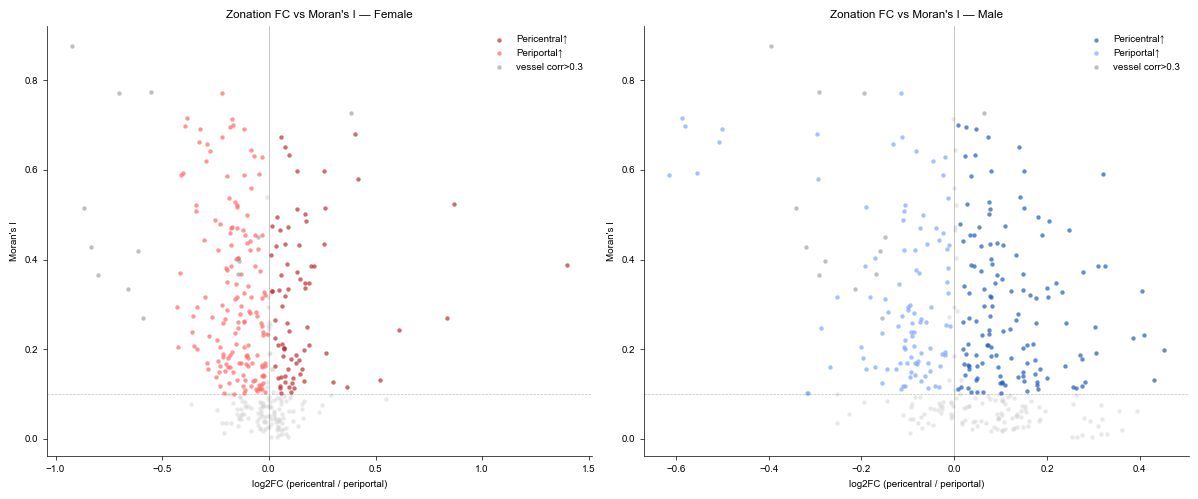

In [49]:
# Zonation FC (PC/PP) vs Moran's I — per sex
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
df = adata.var.copy()
df['moranI'] = df[[f'moranI_{r}' for r in tissue_rois]].max(axis=1)
sv     = df['spatially_variable']
vessel = df['vessel_corr'] > vessel_corr_thresh

for ax, fc_key, pval_key, title, c_pc, c_pp in [
    (axes[0], 'logfc_pericentral_vs_periportal_female', 'pval_pericentral_vs_periportal_female',
     'Female', '#bf2e2e', '#ff6969'),
    (axes[1], 'logfc_pericentral_vs_periportal_male',   'pval_pericentral_vs_periportal_male',
     'Male',   '#205cbc', '#7ba7ff'),
]:
    sig = df[pval_key] < 0.05
    fc  = df[fc_key]

    ax.scatter(df.loc[~sig | ~sv, fc_key], df.loc[~sig | ~sv, 'moranI'],
               c='lightgrey', s=10, alpha=0.5, linewidths=0)
    ax.scatter(df.loc[sig & sv & ~vessel & (fc > 0), fc_key],
               df.loc[sig & sv & ~vessel & (fc > 0), 'moranI'],
               c=c_pc, s=10, alpha=0.7, linewidths=0, label='Pericentral↑')
    ax.scatter(df.loc[sig & sv & ~vessel & (fc < 0), fc_key],
               df.loc[sig & sv & ~vessel & (fc < 0), 'moranI'],
               c=c_pp, s=10, alpha=0.7, linewidths=0, label='Periportal↑')
    ax.scatter(df.loc[vessel, fc_key], df.loc[vessel, 'moranI'],
               c='grey', s=10, alpha=0.5, linewidths=0,
               label=f'vessel corr>{vessel_corr_thresh}')

    ax.axvline(0,   ls='-',  lw=0.5, c='black', alpha=0.3)
    ax.axhline(0.1, ls='--', lw=0.5, c='grey',  alpha=0.5)
    ax.set_xlabel('log2FC (pericentral / periportal)')
    ax.set_ylabel("Moran's I")
    ax.set_title(f"Zonation FC vs Moran's I — {title}")
    ax.legend(fontsize=7, frameon=False)
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(p_results / 'FC_vs_moranI_zonation.pdf', dpi=300, bbox_inches='tight')
plt.show()

C:\Users\TOF-User\AppData\Local\Temp\ipykernel_9520\4079056018.py:29: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\TOF-User\AppData\Local\Temp\ipykernel_9520\4079056018.py:30: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(p_results / 'auc_female_vs_male_by_zone_sexFC.pdf', dpi=300, bbox_inches='tight')
C:\Users\TOF-User\AppData\Local\Temp\ipykernel_9520\4079056018.py:30: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(p_results / 'auc_female_vs_male_by_zone_sexFC.pdf', dpi=300, bbox_inches='tight')
C:\Users\TOF-User\anaconda3\envs\scils_api\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


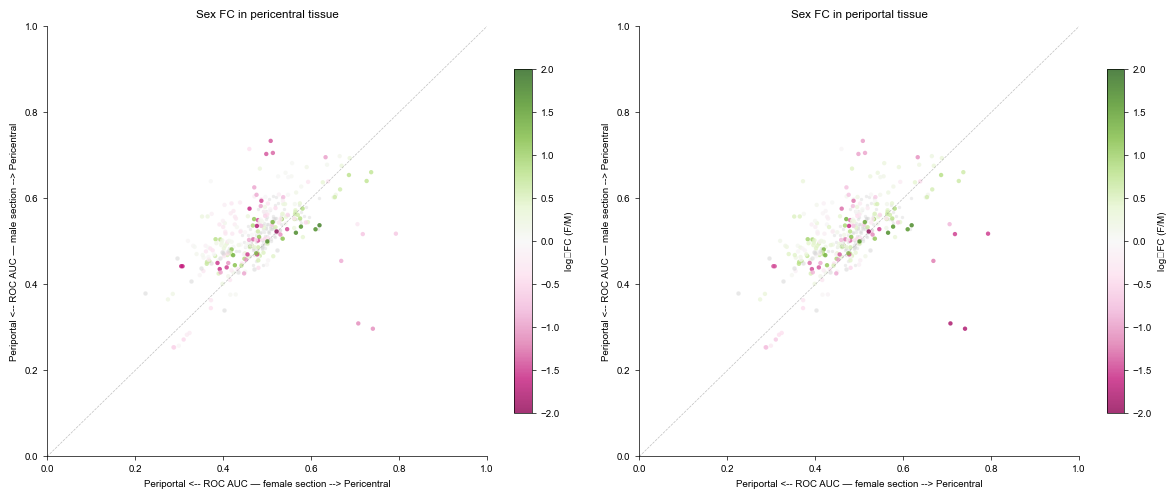

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
df = adata.var.copy()
df['auc_female'] = df[f'zone_auc_{roi_female}']
df['auc_male']   = df[f'zone_auc_{roi_male}']
sv     = df['spatially_variable']
vessel = df['vessel_corr'] > vessel_corr_thresh
fc_lim = 2

for ax, fc_key, title in [
    (axes[0], 'logfc_F_vs_M_pericentral', 'Sex FC in pericentral tissue'),
    (axes[1], 'logfc_F_vs_M_periportal',  'Sex FC in periportal tissue'),
]:
    ax.scatter(df.loc[~sv, 'auc_female'], df.loc[~sv, 'auc_male'],
               c='lightgrey', s=6, alpha=0.4, linewidths=0, zorder=1)
    sc = ax.scatter(df.loc[sv & ~vessel, 'auc_female'], df.loc[sv & ~vessel, 'auc_male'],
                    c=df.loc[sv & ~vessel, fc_key], cmap='PiYG',
                    vmin=-fc_lim, vmax=fc_lim,
                    s=10, alpha=0.8, linewidths=0, zorder=2)
    ax.scatter(df.loc[vessel, 'auc_female'], df.loc[vessel, 'auc_male'],
               c='lightgrey', s=10, alpha=0.5, linewidths=0, zorder=3)
    plt.colorbar(sc, ax=ax, label='log₂FC (F/M)', shrink=0.8)
    ax.axline((0, 0), slope=1, ls='--', lw=0.5, c='grey', alpha=0.5)
    ax.set_xlabel('Periportal <-- ROC AUC — female section --> Pericentral')
    ax.set_ylabel('Periportal <-- ROC AUC — male section --> Pericentral')
    ax.set_title(title)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(p_results / 'auc_female_vs_male_by_zone_sexFC.pdf', dpi=300, bbox_inches='tight')
plt.show()

---
# Section 9 — Stats

All counts restricted to **spatially variable ions** (Moran's I > 0.1, permutation p < 0.05 in ≥ 1 section) and **excluding vessel-enriched ions** (Pearson r vs heme+bile reference > `vessel_corr_thresh`).

### Zonation
- |log2FC (pericentral / periportal)| ≥ 0.5 AND p < 0.05
- Assessed independently in female and male

### Sex differences
- |log2FC (female / male)| ≥ 1.0 AND p < 0.05
- Assessed independently in pericentral and periportal tissue

| Metric | Definition |
|--------|------------|
| Spatially variable | Moran's I > 0.1, p < 0.05 in ≥ 1 section |
| Vessel-enriched | Pearson r vs heme+bile > `vessel_corr_thresh` (excluded from all counts) |
| Zonated (female) | SV, non-vessel, log2FC PC/PP female ≥ 0.5, p < 0.05 |
| Zonated (male) | SV, non-vessel, log2FC PC/PP male ≥ 0.5, p < 0.05 |
| Zonated (either) | Zonated in female OR male |
| Female↑ pericentral | SV, non-vessel, log2FC F/M ≥ 1.0, p < 0.05 in pericentral |
| Male↑ pericentral | SV, non-vessel, log2FC F/M ≤ −1.0, p < 0.05 in pericentral |
| Female↑ periportal | SV, non-vessel, log2FC F/M ≥ 1.0, p < 0.05 in periportal |
| Male↑ periportal | SV, non-vessel, log2FC F/M ≤ −1.0, p < 0.05 in periportal |

In [51]:
logfc_thresh_sex  = 1.0
logfc_thresh_zone = 0.5
pval_thresh       = 0.05

sv     = adata.var['spatially_variable']
vessel = adata.var['vessel_corr'] > vessel_corr_thresh

zonated_female = sv & ~vessel & (adata.var['logfc_pericentral_vs_periportal_female'].abs() >= logfc_thresh_zone) & (adata.var['pval_pericentral_vs_periportal_female'] < pval_thresh)
zonated_male   = sv & ~vessel & (adata.var['logfc_pericentral_vs_periportal_male'].abs()   >= logfc_thresh_zone) & (adata.var['pval_pericentral_vs_periportal_male']   < pval_thresh)
zonated_either = zonated_female | zonated_male

print(f"Total detected lipids:  {adata.n_vars}")
print(f"Spatially variable:     {sv.sum()}")
print(f"Vessel-enriched:        {vessel.sum()}")
print(f"Zonated in female:      {zonated_female.sum()}")
print(f"Zonated in male:        {zonated_male.sum()}")
print(f"Zonated in either sex:  {zonated_either.sum()}")

sex_hits = {}
for zone, fc_key, pval_key in [
    ('pericentral', 'logfc_F_vs_M_pericentral', 'pval_F_vs_M_pericentral'),
    ('periportal',  'logfc_F_vs_M_periportal',  'pval_F_vs_M_periportal'),
]:
    f_up = sv & ~vessel & (adata.var[fc_key] >=  logfc_thresh_sex) & (adata.var[pval_key] < pval_thresh)
    m_up = sv & ~vessel & (adata.var[fc_key] <= -logfc_thresh_sex) & (adata.var[pval_key] < pval_thresh)
    sex_hits[zone] = {'f_up': f_up, 'm_up': m_up}
    print(f"{zone}: Female↑ = {f_up.sum()}, Male↑ = {m_up.sum()}")

sex_regulated_either = (
    sex_hits['pericentral']['f_up'] | sex_hits['pericentral']['m_up'] |
    sex_hits['periportal']['f_up']  | sex_hits['periportal']['m_up']
)
print(f"Sex-regulated in either zone: {sex_regulated_either.sum()}")

Total detected lipids:  373
Spatially variable:     261
Vessel-enriched:        13
Zonated in female:      5
Zonated in male:        6
Zonated in either sex:  11
pericentral: Female↑ = 14, Male↑ = 23
periportal: Female↑ = 14, Male↑ = 22
Sex-regulated in either zone: 41


---
# Section 10 — Export to SCiLS

Exports spatially variable ions with all computed statistics to the SCiLS `.slx` file.

In [53]:
cols_to_export = [
    'logfc_F_vs_M_pericentral',               'pval_F_vs_M_pericentral',
    'logfc_F_vs_M_periportal',                'pval_F_vs_M_periportal',
    'logfc_pericentral_vs_periportal_female', 'pval_pericentral_vs_periportal_female',
    'logfc_pericentral_vs_periportal_male',   'pval_pericentral_vs_periportal_male',
    f'moranI_{roi_female}', f'moranI_{roi_male}',
    f'moranI_pval_{roi_female}', f'moranI_pval_{roi_male}',
    'spatially_variable', 'vessel_corr',
    f'zone_auc_{roi_female}', f'zone_auc_{roi_male}'
]
cols_to_export = [c for c in cols_to_export if c in adata.var.columns]

for roi_label in tissue_rois:
    col  = f'mean_intensity_{roi_label}'
    mask = adata.obs['ROI'] == roi_label
    adata.var[col] = np.array(adata.raw.X[mask].mean(axis=0)).flatten()
    cols_to_export.append(col)

sv_var = adata.var[adata.var['spatially_variable']]

with LocalSession(filename=str(p_scils)) as session:
    import_group_to_scils(
        session,
        feature_list_name='zonation_sex_diff_spatially_variable',
        names=sv_var['feature_name'].values,
        mzs=sv_var[['mz_low', 'mz_high']],
        columns={col: sv_var[col].astype(float).values
                 for col in cols_to_export if col in sv_var.columns}
    )
    print(f"Written: {len(sv_var)} spatially variable ions")

Written: 261 spatially variable ions
